# Lab 4-02：用 networkx 做圖檢索與多跳查詢

**目標**：把上一本存下的三元組建成 networkx 圖，用它內建的走訪函式完成「從問題找到實體 → 沿著邊走幾步 → 把子圖念成文字 → 交給 LLM 回答」。

**你會學到**
- 圖就是「節點＋有方向、有型別的邊」，networkx 一行建好
- 一跳、多跳、最短路徑都有現成函式：`ego_graph`、`single_source_shortest_path_length`、`shortest_path`、`bfs_layers`
- 超級節點：一個大團體會把整張圖拉進來，要有展開規則
- 子圖轉成句子，才是 LLM 讀得懂的上下文

**前置**：先讀 `00_concepts.md`（知識圖譜、多跳、超級節點）。Lab 4-01 已產生 `data/triples.json`（資料夾裡已附一份，可以直接跑）。

**對應投影片**：「從向量到圖：搭橋」「向量 RAG 答不了的兩種題」「Local Search 實體入口」「Lab 4 多跳提問流程」

![圖檢索流程](images/graph_bfs.jpg)

*圖：由左往右讀。先在問題裡找出實體（騙人布），再沿著朱紅色的邊走：騙人布 → 父親耶穌布 → 紅髮海賊團 ← 船長香克斯；走到的子圖轉成文字，交給 LLM 回答。*

## Step 1：先看沒有圖的時候

直接問模型一個要串三件事才答得出來的問題。

In [1]:
import os

from openai import OpenAI

# Ollama 同時有很多人在用時回應會慢；直接用 OpenAI SDK 連本機，給長一點的逾時
client = OpenAI(base_url=os.getenv("LOCAL_BASE_URL", "http://localhost:11434/v1"), api_key="ollama", timeout=300)
MODEL = os.getenv("LOCAL_MODEL", "qwen2.5:3b")


def chat(messages: list[dict]) -> str:
    return client.chat.completions.create(model=MODEL, messages=messages, temperature=0).choices[0].message.content


QUESTION = "騙人布的父親所在海賊團的船長是誰？"
print(chat([{"role": "user", "content": QUESTION + "用一句話回答。"}]))

騙人布的父親是海賊王索隆的船長，即四皇之首卡爾卡斯。


3B 模型對海賊王的知識很零碎，答案通常是錯的，而且講得很有自信。
模組 3 的做法是撈段落給它看；這一本換個方式：把知識整理成圖，讓程式沿著關係走。

## Step 2：讀三元組，建圖

networkx 的 `MultiDiGraph`：有方向（魯夫 → 草帽海賊團），而且兩個節點之間可以有多條不同關係的邊。
節點屬性 `label` 是類型（Person、Crew…），邊屬性 `relation` 是關係名稱。

In [2]:
import json
from pathlib import Path

import networkx as nx

data = json.loads(Path("data/triples.json").read_text(encoding="utf-8"))

G = nx.MultiDiGraph()
G.add_nodes_from((n["name"], {"label": n["label"], "aliases": n["aliases"]}) for n in data["nodes"])
G.add_edges_from((t["subject"], t["object"], {"relation": t["relation"]}) for t in data["triples"])

print(f"{G.number_of_nodes()} 個節點，{G.number_of_edges()} 條邊")
print("魯夫：", G.nodes["魯夫"])

187 個節點，182 條邊
魯夫： {'label': 'Person', 'aliases': ['蒙其·D·魯夫', '草帽小子', '橡膠人']}


## Step 3：把整張圖畫出來

顏色對應類型，跟投影片「Lab 4 圖譜長相」一致：藍＝人物、黃＝海賊團、紅＝寶物；另外兩種是夢想與地方。

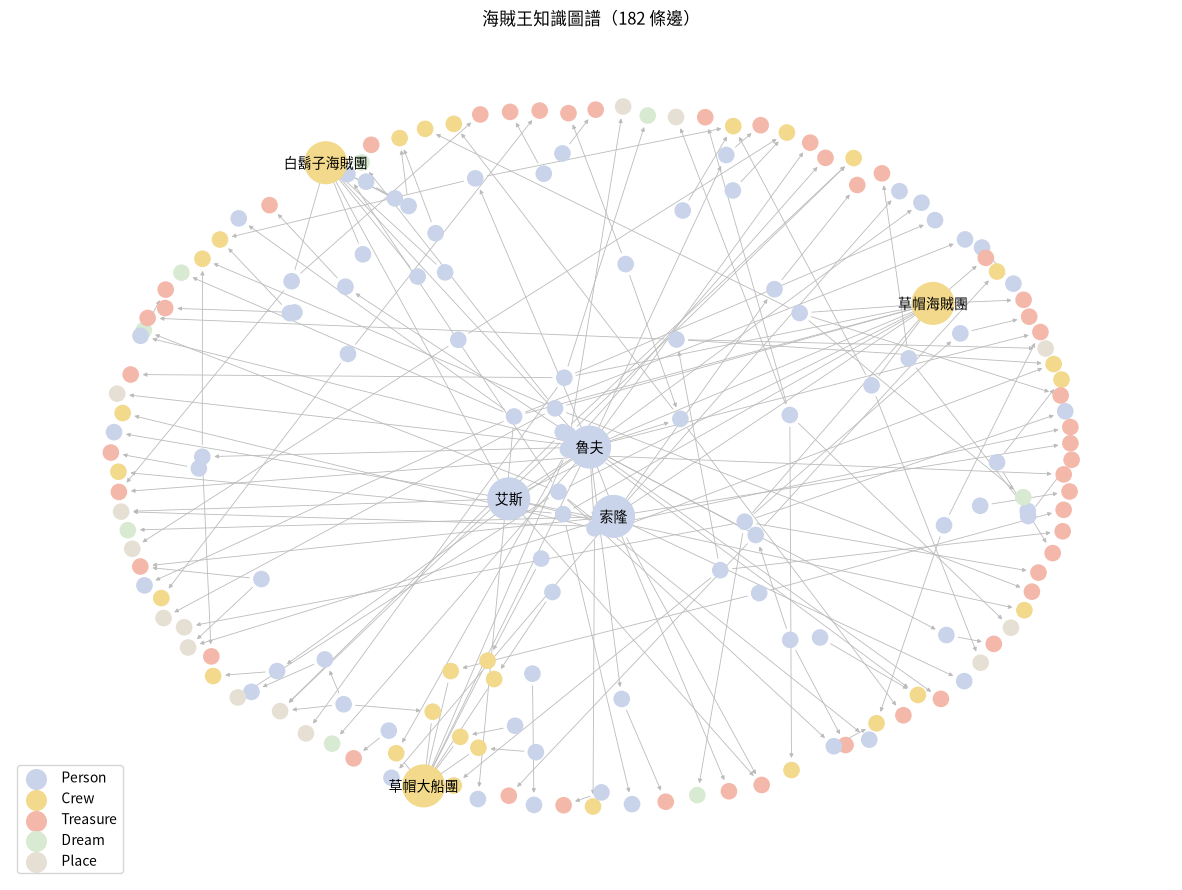

In [3]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

COLORS = {"Person": "#c9d3ea", "Crew": "#f2d98b", "Treasure": "#f4b8aa", "Dream": "#d9ead3", "Place": "#e6e0d4"}
FONT = plt.rcParams["font.sans-serif"][0]

pos = nx.spring_layout(G, seed=7, k=0.9, iterations=300)  # k 越大節點越分散
hubs = {n for n, d in G.degree if d >= 8}  # 節點太多，只標出連最多邊的幾個
plt.figure(figsize=(15, 11))
nx.draw_networkx_nodes(G, pos, node_color=[COLORS[G.nodes[n]["label"]] for n in G],
                       node_size=[900 if n in hubs else 120 for n in G])
nx.draw_networkx_labels(G, pos, labels={n: n for n in hubs}, font_size=10, font_family=FONT)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=6, edge_color="#bbb", width=0.6)
for label, color in COLORS.items():
    plt.scatter([], [], c=color, s=200, label=label)
plt.legend(loc="lower left")
plt.axis("off")
plt.title(f"海賊王知識圖譜（{G.number_of_edges()} 條邊）")
plt.show()

圖上只標了連最多邊的幾個節點：魯夫、草帽海賊團、草帽大船團、白鬍子海賊團……幾乎每條故事線都會經過它們。這個觀察在 Step 7 會變成一個問題。

## Step 4：一跳——`ego_graph` 取出某個節點周圍的子圖

圖檢索最小的動作：給一個節點，拿出它周圍一圈。`nx.ego_graph(G, 節點, radius=1)` 回傳以它為中心、半徑 1 的子圖。
`undirected=True` 表示出邊、入邊都算（「騙人布的父親是耶穌布」和「耶穌布是紅髮海賊團的成員」方向不同，都要拿）。
子圖本身還是 networkx 的圖，直接把它的邊印出來。

In [4]:
def show_edges(graph: nx.MultiDiGraph) -> None:
    for u, v, rel in graph.edges(data="relation"):
        print(f"  {u} -[{rel}]-> {v}")


for center in ["騙人布", "紅髮海賊團"]:
    ego = nx.ego_graph(G, center, radius=1, undirected=True)
    print(f"{center}（{ego.number_of_nodes()} 個節點、{ego.number_of_edges()} 條邊）：")
    show_edges(ego)

騙人布（7 個節點、6 條邊）：
  騙人布 -[FROM]-> 西羅布村
  騙人布 -[MEMBER_OF]-> 草帽海賊團
  騙人布 -[DREAMS_OF]-> 勇敢的海上戰士
  騙人布 -[HAS_FATHER]-> 耶穌布
  騙人布 -[DEFEATED]-> 佩羅娜
  騙人布 -[DEFEATED]-> 砂糖
紅髮海賊團（3 個節點、2 條邊）：
  香克斯 -[CAPTAIN_OF]-> 紅髮海賊團
  耶穌布 -[MEMBER_OF]-> 紅髮海賊團


## Step 5：多跳——最短路徑直接把答案那條路找出來

`QUESTION` 要從騙人布走到某個船長。如果已經知道終點，`nx.shortest_path` 一行就找到路；
方向不重要（「耶穌布是紅髮海賊團的成員」和「香克斯是紅髮海賊團的船長」箭頭都指向海賊團），所以先轉成無向的檢視。

In [5]:
U = G.to_undirected(as_view=True)  # 只是檢視，不複製資料

path = nx.shortest_path(U, "騙人布", "香克斯")
print(" → ".join(path))
for a, b in zip(path, path[1:]):
    for u, v, rel in G.edges([a, b], data="relation"):
        if {u, v} == {a, b}:
            print(f"  {u} -[{rel}]-> {v}")

騙人布 → 耶穌布 → 紅髮海賊團 → 香克斯
  騙人布 -[HAS_FATHER]-> 耶穌布
  耶穌布 -[MEMBER_OF]-> 紅髮海賊團
  香克斯 -[CAPTAIN_OF]-> 紅髮海賊團


三跳：騙人布 →（父親）耶穌布 →（成員）紅髮海賊團 ←（船長）香克斯。
向量檢索要撈到三段不同的描述，再靠模型自己拼；圖只要沿著邊走，答案就在路上。

但真實的問題裡不會告訴你終點是誰。我們只知道起點，得「往外走幾步，把走到的都拿出來」。

## Step 6：不知道終點時——從起點一圈一圈往外

`nx.single_source_shortest_path_length(U, 起點, cutoff=k)` 回傳「k 步內走得到的每個節點，以及它離起點幾步」。
這就是廣度優先搜尋（BFS），networkx 幫你寫好了。

In [6]:
dist = nx.single_source_shortest_path_length(U, "騙人布", cutoff=3)
for k in range(4):
    print(f"第 {k} 步：", [n for n, d in dist.items() if d == k])

第 0 步： ['騙人布']
第 1 步： ['草帽海賊團', '佩羅娜', '砂糖', '耶穌布', '西羅布村', '勇敢的海上戰士']
第 2 步： ['佛朗基', '喬巴', '黃金梅利號', '吉貝爾', '索隆', '香吉士', '羅賓', '布魯克', '娜美', '千陽號', '魯夫', '幽靈果實', '紅髮海賊團']
第 3 步： ['佛朗基家族', '福克斯', '人人果實', '熊鬥', '磁鼓島', '能治百病的醫生', '魚人島', '太陽海賊團', '琵卡', '閻魔', '霜月村', '龍馬', '一先生', '世界第一大劍豪', '角', '和道一文字', '秋水', '奎因', 'All Blue', '加布拉', '文斯莫克·加治', '蕾玖', '巴洛克工作社', '花花果實', '歐哈拉', '讀懂歷史本文', '倫巴海賊團', '與拉布重逢', '黃泉果實', '阿布薩羅姆', '天候棒', '卡莉法', '畫出全世界的地圖', '可可亞西村', '草帽大船團', '艾涅爾', '多拉格', '艾斯', '克洛克達爾', '摩利亞', '荷帝·瓊斯', '風車村', '多佛朗明哥', '凱撒·庫朗', '凱多', '阿龍', '卡塔庫栗', '三先生', '薩波', '橡膠果實', '海賊王', '人人果實．幻獸種．模型「尼卡」', '草帽', '路基', '香克斯']


In [7]:
for hops in [1, 2, 3, 4]:
    ego = nx.ego_graph(G, "騙人布", radius=hops, undirected=True)
    print(f"走 {hops} 步：{ego.number_of_nodes():>2} 個節點，{ego.number_of_edges():>2} 條邊（整張圖 {G.number_of_edges()} 條）")

走 1 步： 7 個節點， 6 條邊（整張圖 182 條）
走 2 步：20 個節點，19 條邊（整張圖 182 條）
走 3 步：75 個節點，78 條邊（整張圖 182 條）
走 4 步：111 個節點，119 條邊（整張圖 182 條）


答案（香克斯）在第 3 步。可是節點數每多走一步就暴增，走 4 步時已經摸到圖的一大半。為什麼？

## Step 7：先看它壞掉——超級節點

騙人布第 1 步就碰到「草帽海賊團」，第 2 步從它展開，就把十幾個成員全拉進來，
第 3 步再把每個成員的果實、夢想、故鄉、打倒過的對手都拉進來。這種連著一大堆邊的節點叫**超級節點**（hub）。

塞整張圖給 LLM，等於回到「把全部文件塞進 prompt」：貴，而且小模型會被無關的事實干擾。`G.degree` 直接告訴你誰是 hub。

In [8]:
for n, d in sorted(G.degree, key=lambda x: -x[1])[:6]:
    print(f"{n}：{d} 條邊")

魯夫：21 條邊
草帽海賊團：12 條邊
索隆：10 條邊
草帽大船團：9 條邊
白鬍子海賊團：8 條邊
艾斯：8 條邊


修法是加一條展開規則：**走到海賊團，只往它的船長走，不展開全部成員。**
這條規則來自我們對問題的理解：多跳問題問的通常是「某人所屬團體的船長」，很少問「那個團的所有人」。

networkx 沒有「依節點類型決定怎麼展開」的參數，但不用自己寫 BFS：
把規則寫成一張「可以往哪走」的有向圖 `E`，再交給 `nx.bfs_layers` 一層一層走。
規則只有一行：從海賊團往回走，只能走 `CAPTAIN_OF` 那條邊。

In [9]:
def expansion_graph(graph: nx.MultiDiGraph, hub_rule: bool = True) -> nx.DiGraph:
    """可以往哪走：出邊一律可走；入邊反著走時，海賊團只能走回船長。"""
    E = nx.DiGraph()
    for node, label in graph.nodes(data="label"):
        E.add_node(node)
        E.add_edges_from((node, v) for v in graph.successors(node))            # 出邊：一律可走
        E.add_edges_from((node, u) for u, _, rel in graph.in_edges(node, data="relation")
                         if not (hub_rule and label == "Crew" and rel != "CAPTAIN_OF"))  # 入邊：海賊團只走回船長
    return E


E_all, E_pruned = expansion_graph(G, hub_rule=False), expansion_graph(G)
for name, E in [("全部展開", E_all), ("海賊團只找船長", E_pruned)]:
    layers = list(nx.bfs_layers(E, ["騙人布"]))[:4]
    print(f"{name}：", [len(layer) for layer in layers], "← 每一層的節點數")

全部展開： [1, 6, 13, 55] ← 每一層的節點數
海賊團只找船長： [1, 6, 5, 21] ← 每一層的節點數


走到哪些節點有了，還要把「走過的邊」收集起來當上下文：每個在第 k 層的節點，把它允許走的邊記下來，標上第 k+1 步。

In [10]:
def subgraph_edges(starts: list[str], hops: int, E: nx.DiGraph) -> list[tuple[str, str, str, int]]:
    """回傳 (主體, 關係, 客體, 第幾步)；只收 E 允許走的邊。"""
    edges = {}
    for depth, layer in enumerate(nx.bfs_layers(E, starts)):
        if depth >= hops:
            break
        for node in layer:
            incident = list(G.out_edges(node, data="relation")) + list(G.in_edges(node, data="relation"))
            for u, v, rel in incident:
                other = v if u == node else u
                if E.has_edge(node, other):
                    edges.setdefault((u, rel, v), depth + 1)
    return [(*e, hop) for e, hop in edges.items()]


sizes = {"全部展開": [], "海賊團只找船長": []}
for hops in range(1, 5):
    sizes["全部展開"].append(len(subgraph_edges(["騙人布"], hops, E_all)))
    sizes["海賊團只找船長"].append(len(subgraph_edges(["騙人布"], hops, E_pruned)))
print(sizes)

{'全部展開': [6, 19, 74, 117], '海賊團只找船長': [6, 11, 32, 62]}


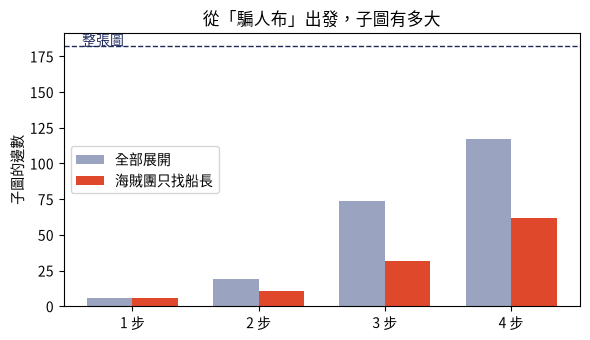

In [11]:
import numpy as np

x = np.arange(1, 5)
plt.figure(figsize=(6, 3.5))
plt.bar(x - 0.18, sizes["全部展開"], width=0.36, label="全部展開", color="#9aa3c0")
plt.bar(x + 0.18, sizes["海賊團只找船長"], width=0.36, label="海賊團只找船長", color="#e0482c")
plt.axhline(G.number_of_edges(), ls="--", c="#1f2a5c", lw=1)
plt.text(0.6, G.number_of_edges() + 1, "整張圖", color="#1f2a5c")
plt.xticks(x, [f"{h} 步" for h in x])
plt.ylabel("子圖的邊數")
plt.title("從「騙人布」出發，子圖有多大")
plt.legend()
plt.tight_layout()
plt.show()

## Step 8：畫出走到的子圖

把剪枝後走 3 步的子圖畫出來，Step 5 找到的那條路用朱紅色標出。

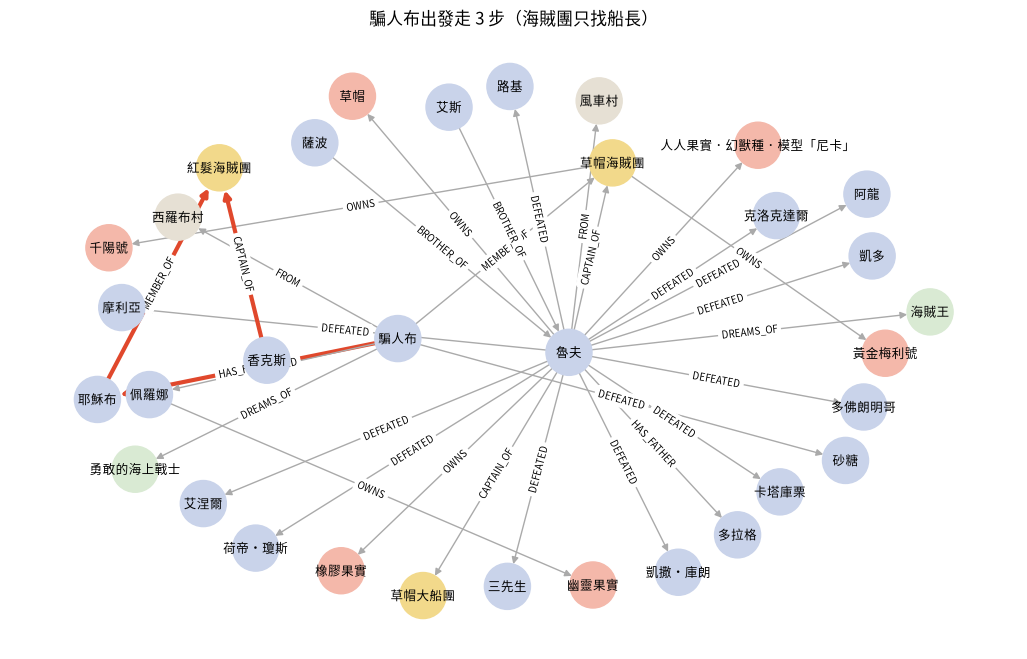

In [12]:
sub_edges = subgraph_edges(["騙人布"], 3, E_pruned)
H = nx.DiGraph()  # 子圖裡同一對節點最多一條邊，用簡單有向圖比較好畫
H.add_edges_from((s, o, {"relation": r}) for s, r, o, _ in sub_edges)

on_path = {frozenset(p) for p in zip(path, path[1:])}
pos = nx.spring_layout(H, seed=3, k=1.2)
plt.figure(figsize=(13, 8))
nx.draw_networkx_nodes(H, pos, node_color=[COLORS[G.nodes[n]["label"]] for n in H], node_size=1100)
nx.draw_networkx_labels(H, pos, font_size=9, font_family=FONT)
nx.draw_networkx_edges(H, pos, edge_color=["#e0482c" if frozenset(e) in on_path else "#aaa" for e in H.edges()],
                       width=[3 if frozenset(e) in on_path else 1 for e in H.edges()], arrows=True, node_size=1100)
nx.draw_networkx_edge_labels(H, pos, edge_labels=nx.get_edge_attributes(H, "relation"), font_size=7, font_family=FONT)
plt.axis("off")
plt.title("騙人布出發走 3 步（海賊團只找船長）")
plt.show()

## Step 9：子圖念成句子

LLM 讀 `(騙人布, HAS_FATHER, 耶穌布)` 也懂，但 3B 小模型讀自然的中文句子準得多。
每種關係配一個句型就好。順序照走訪的步數排，離問題越近的事實越前面。

In [13]:
PHRASES = {
    "CAPTAIN_OF": "{s} 是 {o} 的船長（帶頭的人）",
    "MEMBER_OF": "{s} 是 {o} 的成員",
    "OWNS": "{s} 擁有 {o}",
    "DREAMS_OF": "{s} 的夢想是 {o}",
    "FROM": "{s} 出身 {o}",
    "HAS_FATHER": "{s} 的父親是 {o}",
    "BROTHER_OF": "{s} 是 {o} 的結拜哥哥",
    "DEFEATED": "{s} 打倒了 {o}",
}


def to_text(edges: list[tuple]) -> str:
    return "\n".join(PHRASES[r].format(s=s, o=o) for s, r, o, *_ in edges)


print(to_text(sub_edges))

騙人布 出身 西羅布村
騙人布 是 草帽海賊團 的成員
騙人布 的夢想是 勇敢的海上戰士
騙人布 的父親是 耶穌布
騙人布 打倒了 佩羅娜
騙人布 打倒了 砂糖
草帽海賊團 擁有 黃金梅利號
草帽海賊團 擁有 千陽號
魯夫 是 草帽海賊團 的船長（帶頭的人）
耶穌布 是 紅髮海賊團 的成員
佩羅娜 擁有 幽靈果實
魯夫 出身 風車村
魯夫 擁有 橡膠果實
魯夫 擁有 草帽
魯夫 的夢想是 海賊王
魯夫 打倒了 阿龍
魯夫 是 草帽大船團 的船長（帶頭的人）
魯夫 打倒了 多佛朗明哥
魯夫 打倒了 三先生
魯夫 打倒了 克洛克達爾
魯夫 打倒了 艾涅爾
魯夫 打倒了 路基
魯夫 的父親是 多拉格
魯夫 打倒了 摩利亞
魯夫 打倒了 荷帝·瓊斯
魯夫 打倒了 凱撒·庫朗
魯夫 打倒了 卡塔庫栗
魯夫 擁有 人人果實．幻獸種．模型「尼卡」
魯夫 打倒了 凱多
艾斯 是 魯夫 的結拜哥哥
薩波 是 魯夫 的結拜哥哥
香克斯 是 紅髮海賊團 的船長（帶頭的人）


## Step 10：從問題找到起點

投影片「Local Search」用向量比對實體描述來找入口。我們的圖只有幾十個節點，用字串比對就夠，不需要另外引入套件：
問題裡出現了哪個節點的名字或別名，那個節點就是起點。

要小心一件事：問題提到「白鬍子海賊團」時，「白鬍子」也會被比對到。規則是**被更長名字蓋住的短名字不算**。

In [14]:
def link_entities(question: str) -> list[str]:
    hits = {}
    for name, aliases in G.nodes(data="aliases"):
        for surface in [name, *aliases]:
            if surface in question:
                hits[surface] = name
    surfaces = [s for s in hits if not any(s != o and s in o for o in hits)]
    return sorted({hits[s] for s in surfaces})


for q in [QUESTION, "打倒阿龍的人，夢想是什麼？", "草帽小子出身哪裡？", "白鬍子海賊團的船長是誰？"]:
    print(q, "→", link_entities(q))

騙人布的父親所在海賊團的船長是誰？ → ['騙人布']
打倒阿龍的人，夢想是什麼？ → ['阿龍']
草帽小子出身哪裡？ → ['魯夫']
白鬍子海賊團的船長是誰？ → ['白鬍子海賊團']


「草帽小子」靠的是 Lab 4-01 存下的別名；沒有那張別名表，這個問題就找不到起點。

## Step 11：全部串起來

問題 → 找起點 → 剪枝走訪 → 念成句子 → 交給 LLM。整個流程模型只出場一次（最後組答案），
中間「找誰、走哪」都是確定的程式，可以重跑、可以除錯。

In [15]:
ANSWER_SYSTEM = "只根據提供的資料回答，用一句話。資料沒有就說「資料不足」。"


def graph_answer(question: str, hops: int = 4, verbose: bool = False) -> str:
    starts = link_entities(question)
    context = to_text(subgraph_edges(starts, hops, E_pruned))
    if verbose:
        print(f"起點：{starts}，上下文 {len(context.splitlines())} 句")
    return chat([
        {"role": "system", "content": ANSWER_SYSTEM},
        {"role": "user", "content": f"資料：\n{context}\n\n問題：{question}"},
    ])


print(graph_answer(QUESTION, verbose=True))

起點：['騙人布']，上下文 62 句
騙人布的父親耶穌布是紅髮海賊團的成員，而香克斯是紅髮海賈的船長。所以騙人布的父親所在海賊團的船長是香克斯。


In [16]:
for q in ["和索隆同一個海賊團的船長，夢想是什麼？", "打倒阿龍的人，夢想是什麼？", "巴托洛米奧所屬大船團的帶頭人，出身哪個村子？"]:
    print(q)
    print("  →", graph_answer(q, verbose=True))

和索隆同一個海賊團的船長，夢想是什麼？
起點：['索隆']，上下文 66 句
  → 魯夫是草帽海賊團的船長，他的夢想是海賊王。因此，和索隆同一個海賊團的船長，夢想是海賊王。
打倒阿龍的人，夢想是什麼？
起點：['阿龍']，上下文 65 句
  → 魯夫 打倒了 阿龍，而魯夫的夢想是海賊王。因此，打倒阿龍的人，夢想是海賊王。
巴托洛米奧所屬大船團的帶頭人，出身哪個村子？
起點：['巴托洛米奧']，上下文 58 句
  → 巴托洛米奧出身東海，而草帽大船團的帶頭人魯夫出身風車村，所以無法直接回答巴托洛米奧出身哪個村子。資料中沒有提供這方面的信息。資料不足。


檢索這一半是穩的：答案需要的事實一定在上下文裡（可以把 `to_text(subgraph_edges(...))` 印出來自己確認）。
剩下的錯誤來自 3B 模型讀了六十幾句之後還是串錯（例如巴托洛米奧那題，它被「巴托洛米奧出身東海」帶偏），這是「生成」的問題，不是「檢索」的問題。
Lab 4-04 會用 14 題把兩種檢索正式比一次。

上面寫的函式整理在同資料夾的 `graph_retrieval.py`，Lab 4-04 直接 import。

## 試試看

1. 把 `graph_answer` 裡的 `E_pruned` 換成 `E_all`（不剪枝）再問一次 `QUESTION`。上下文變多少句？答案有變嗎？
2. 問「和魯夫同一個海賊團的人有誰？」。剪枝規則讓它答不出來，為什麼？你會怎麼讓兩種問題都能答？（提示：依問題挑不同的 `E`）
3. 用 `nx.all_simple_paths(U, "騙人布", "香克斯", cutoff=4)` 列出所有不超過 4 步的路。除了 Step 5 那條，還有別的路嗎？

## 小結

- 圖檢索的核心只有三步：從問題找起點、沿著邊走、把走到的子圖念成文字；走訪交給 networkx（`ego_graph`、`shortest_path`、`bfs_layers`）。
- 遇到超級節點一定要有展開規則，否則子圖會變成整張圖；規則寫成一張「可以往哪走」的圖，走訪照樣用內建函式。
- networkx 適合小圖與理解，資料一大就需要真正的圖資料庫。下一本把同一份三元組匯入 Neo4j，用 Cypher 查。